In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import scienceplots
from network_creation.stats.topology_welfare import (
    normalized_welfare_per_topology,
    get_ER_normalized_welfare,
)
from typing import List

plt.style.use("science")

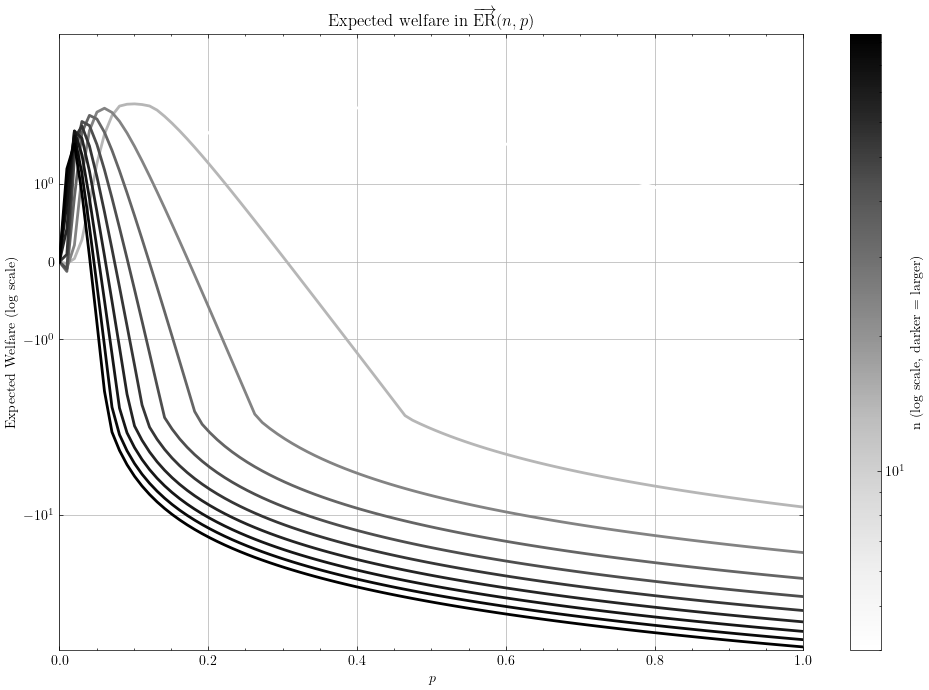

In [2]:
N_values = np.arange(4, 100, 10, dtype=int)
p_values = np.linspace(0, 1, 100, dtype=float)

results = np.zeros((len(N_values), len(p_values)))
for i, N in enumerate(N_values):
    for j, p in enumerate(p_values):
        results[i, j] = get_ER_normalized_welfare(
            n=N,
            benefit_to_cost_ratio=10 / (2 * N),
            p_directed=p,
            distance_discount=0.9,
            epsilon=1e-9,
        )

fig, ax = plt.subplots(figsize=(12, 8))

norm = LogNorm(vmin=N_values.min(), vmax=N_values.max())
cmap = plt.cm.Greys

for i, N in enumerate(N_values):
    ax.plot(p_values, results[i], color=cmap(norm(N)), linewidth=2)

ax.set_title(r"Expected welfare in $\overrightarrow{\mathrm{ER}}(n,p)$")
ax.set_xlabel(r"$p$")
ax.set_ylabel("Expected Welfare (log scale)")
ax.set_xlim(0, 1)
ax.set_yscale("symlog")
ax.grid(True)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, label="n (log scale, darker = larger)")

plt.show()

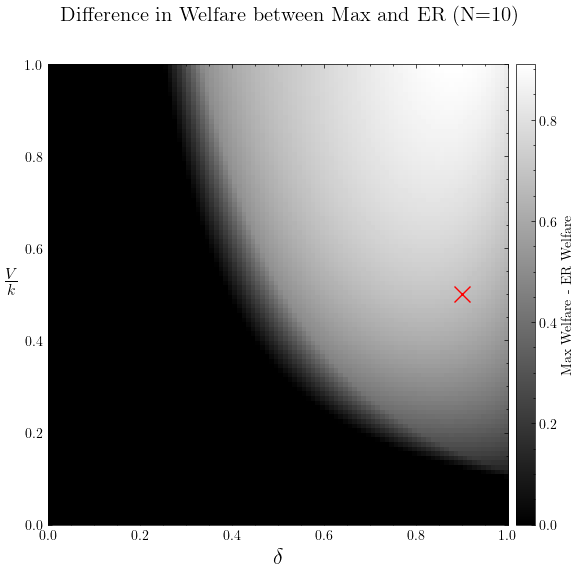

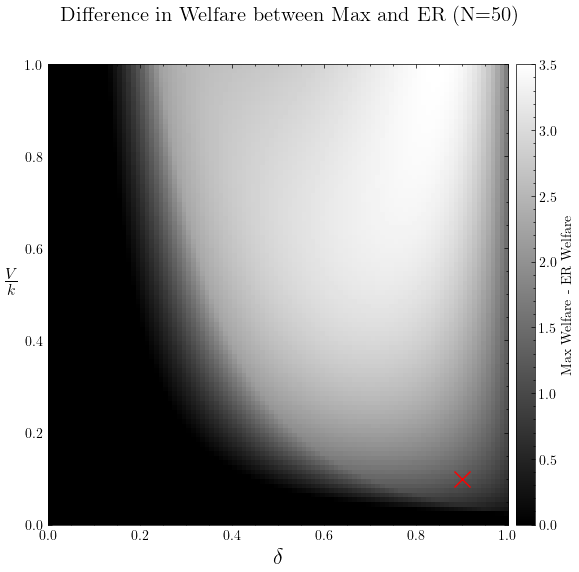

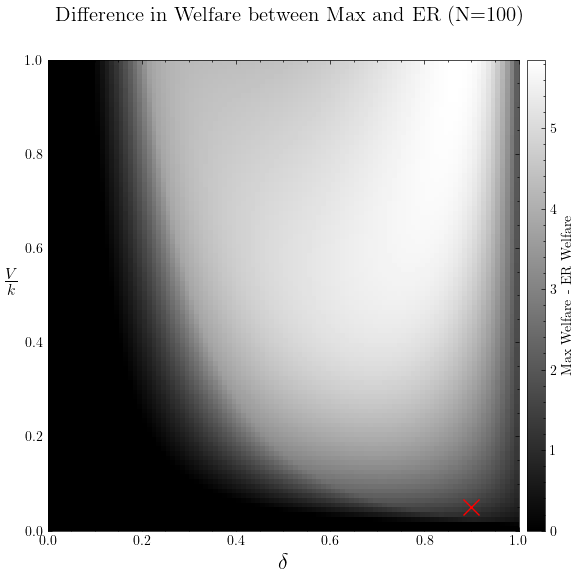

In [3]:
num = 100
benefit_to_cost_ratio_values = np.linspace(0.001, 0.999, num)
distance_discount_values = np.linspace(0.001, 0.999, num)

for N in [10, 50, 100]:
    max_payoff = np.array(
        [
            [
                normalized_welfare_per_topology(
                    topology_class="max",
                    n=N,
                    benefit_to_cost_ratio=v,
                    distance_discount=d,
                )
                for d in distance_discount_values
            ]
            for v in benefit_to_cost_ratio_values
        ],
        dtype=float,
    )
    er_payoff = np.array(
        [
            [
                normalized_welfare_per_topology(
                    topology_class="random",
                    n=N,
                    benefit_to_cost_ratio=v,
                    distance_discount=d,
                )
                for d in distance_discount_values
            ]
            for v in benefit_to_cost_ratio_values
        ],
        dtype=float,
    )
    diff = max_payoff - er_payoff

    ncols = 1
    fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(6 * ncols, 6), sharex=True, sharey=True)  # type: ignore
    if ncols == 1:
        ax: List[plt.Axes] = [ax]

    im0 = ax[0].imshow(
        diff,
        origin="lower",
        aspect="equal",
        extent=(0.0, 1.0, 0.0, 1.0),
        cmap="gray",
    )
    ax[0].set_box_aspect(1)
    div0 = make_axes_locatable(ax[0])
    cax0 = div0.append_axes("right", size="4%", pad=0.08)
    fig.colorbar(im0, cax=cax0, label="Max Welfare - ER Welfare")
    ax[0].set_xlabel(r"$\delta$", size=16)
    ax[0].set_ylabel(r"$\frac{V}{k}$", size=16, rotation=0, labelpad=10)
    ax[0].plot(0.9, 10 / (2 * N), "x", color="red", markersize=12)

    fig.suptitle(f"Difference in Welfare between Max and ER (N={N})", size=15)
    plt.tight_layout()
    plt.show()

In [4]:
distance_discount = 0.9
for N in [10, 50, 100]:
    benefit_to_cost_ratio = 10 / (2 * N)
    max_normalized_welfare = normalized_welfare_per_topology(
        topology_class="max",
        n=N,
        benefit_to_cost_ratio=benefit_to_cost_ratio,
        distance_discount=distance_discount,
    )
    er_normalized_welfare = normalized_welfare_per_topology(
        topology_class="random",
        n=N,
        benefit_to_cost_ratio=benefit_to_cost_ratio,
        distance_discount=distance_discount,
    )
    print(
        f"N={N}: Max Welfare = {max_normalized_welfare:.4f}, ER Welfare = {er_normalized_welfare:.4f}, Difference = {max_normalized_welfare - er_normalized_welfare:.4f}"
    )

N=10: Max Welfare = 2.8260, ER Welfare = 2.1427, Difference = 0.6833
N=50: Max Welfare = 3.0066, ER Welfare = 1.7911, Difference = 1.2156
N=100: Max Welfare = 3.0284, ER Welfare = 1.6025, Difference = 1.4259
